# **Notebook 3: SQL Feature Ablation and Alert-Budget Sensitivity**

**Overall Notebook Description:** Test which groups of SQL-derived features influence the fixed logistic
baseline, then measure how benign-calibration alert budgets change detection and false
alerts. Keep the source, chronological roles, preprocessing and estimator configuration fixed.
Compare the learned baseline with the existing SQL rules and inspect their errors.

**Question:** How sensitive are the observed decisions to feature availability and the
false-alert budget? All predefined variants and budgets are reported. This experiment
describes the existing Tuesday development population; it does not choose a production model.

---

# **Part 1: Configuration**

**Part 1 Description:** Use the same frozen input hashes as Notebooks 1 and 2. Training fits the imputer, log transform,
scaler and logistic estimator. Known-benign calibration windows determine cutoffs with the
existing conservative tie rule. Development windows supply the reported outcomes only.
Unknown-label windows are excluded from all three roles.

The primary ablation comparison retains the existing 1% calibration budget. The sensitivity
grid is fixed at 0.1%, 0.5%, 1% and 2%; every scenario is displayed. Integer counts and tied
scores can leave an achieved calibration rate below its budget. A calibration budget is
not a guarantee about development or future false alerts.

### **Imports, Project Root, and Frozen Inputs**

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from cybershield.db import ROOT, file_hash
from cybershield.research import RESEARCH, load_snapshot, split_masks
from cybershield.evaluate import FEATURES
data, protocol, manifest = load_snapshot()
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
FIGURES = RESEARCH / 'figures'; FIGURES.mkdir(exist_ok=True)
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
display(pd.Series(manifest, name='Frozen experiment').drop('files').to_frame())

,Frozen experiment
experiment_id,45b7feae-ffe5-4c71-998c-b87afe724bd6
feature_run_id,464b8de2-25da-4368-9333-eeade277dc70
schema,cs_tuesday
snapshot_created_utc,2026-10-25T03:12:01.622526+00:00
source_run_directory,reports\runs\real_20261025T022514Z_660a4c30
read_only_research,True


### **Configurations and Experimental Controls**

In [2]:
from cybershield.robustness import (
    ALERT_TARGETS, FEATURE_GROUPS, SQL_CONTROLS, feature_variants, run_robustness,
)
masks = split_masks(data, protocol['config'])
print('Fixed logistic configuration:', protocol['config']['model'])
print('Seed:', protocol['config']['seed'])
print('Budget scenarios:', ALERT_TARGETS)
display(pd.Series(protocol['config']['splits']).to_frame('Recorded-clock interval'))
display(pd.Series(FEATURE_GROUPS).to_frame('SQL-derived feature groups'))

Fixed logistic configuration: {'C': 1.0, 'class_weight': 'balanced', 'solver': 'lbfgs', 'max_iter': 2000}
Seed: 1729
Budget scenarios: (0.001, 0.005, 0.01, 0.02)


,Recorded-clock interval
train,"[2017-07-04 08:55:00, 2017-07-04 09:45:00]"
calibration,"[2017-07-04 09:45:00, 2017-07-04 10:00:00]"
development,"[2017-07-04 10:00:00, 2017-07-04 11:00:00]"


,SQL-derived feature groups
volume,[flow_count]
diversity,"[unique_ports, unique_destinations]"
services,[service_flows]
size_duration,"[packets, bytes, mean_duration_us]"


---

# **Part 2: Model Setup**

**Part 2 Description:** Refit the same logistic model using all seven features, after removing each of four semantic
groups, and using flow count alone. Removing a group can change the fitted model and its
calibrated cutoff. These are matched system comparisons, not causal feature importance;
correlated features can substitute for a removed signal.

`service_flows` counts ports 21/22, directly relevant to this Tuesday FTP campaign. Testing
its removal helps expose reliance on capture-specific service information. Raw source IP,
timestamps, retrospective labels and prior model scores never enter the estimator.
The SQL controls reuse their saved training-fitted scales and receive the same benign-only
budget calibration. The port-diversity rule keeps its minimum-flow gate.

### **Define Controlled Feature Removals and SQL References**

In [3]:
variants = feature_variants()
display(pd.DataFrame([
    {'variant': name, 'feature_count': len(features), 'features': ', '.join(features)}
    for name, features in variants.items()
]))
print('SQL quality references:', SQL_CONTROLS)
print((ROOT / 'sql/detection/scores.sql').read_text())
print((ROOT / 'sql/features/source_windows.sql').read_text())

,variant,feature_count,features
0,LR: all features,7,"flow_count, unique_ports, unique_destinations,..."
1,LR: without volume,6,"unique_ports, unique_destinations, service_flo..."
2,LR: without diversity,5,"flow_count, service_flows, packets, bytes, mea..."
3,LR: without services,6,"flow_count, unique_ports, unique_destinations,..."
4,LR: without size_duration,4,"flow_count, unique_ports, unique_destinations,..."
5,LR: flow count only,1,flow_count


SQL quality references: ('sql_combined', 'rule_volume', 'rule_ports', 'rule_services')
-- Native interpretable rule scores. Gates/scales are versioned per experiment.
WITH scores AS (
SELECT feature_run_id,host(src_ip) AS src_ip,window_start,
       flow_count / %(volume_scale)s::float8 AS rule_volume,
       CASE WHEN flow_count >= 10 THEN unique_ports / %(ports_scale)s::float8 ELSE 0 END AS rule_ports,
       service_flows / %(services_scale)s::float8 AS rule_services
FROM window_features WHERE feature_run_id=%(feature_run_id)s
)
SELECT *,greatest(rule_volume,rule_ports,rule_services) AS sql_combined
FROM scores ORDER BY window_start,src_ip;


-- One active source per five-minute availability-proxy window.
-- Labels are deliberately absent. Historical mean covers observed ACTIVE windows;
-- it does not fabricate zeros or claim complete sensor coverage.
WITH buckets AS (
    SELECT src_ip,date_bin(interval '5 minutes',reported_end,timestamp '2000-01-01') AS window_start,
           co

---

# **Part 3: Run the Experiments**

**Part 3 Description:** Run six independent fits, each on training rows only, under one requested compute thread.
Four saved SQL scores serve as additional quality controls. Each of the ten methods is
evaluated at all four alert budgets. No hyperparameter search, development early stopping,
best-budget selection or final-holdout evaluation is performed.

Outputs include the complete budget grid, matched ablations, support counts, per-window
calibration/development scores, reference decisions and fitted preprocessing parameters.
Input-data, protocol and implementation hashes bind the experiment record.

At the original 1% budget, the full-feature logistic fit and combined SQL rule should reproduce
the frozen decisions. This connects the new experiment to the existing evidence rather than
silently changing its population or decision rule.

### **Fit Each Variant and Calibrate Every Budget**

In [4]:
results, ablations, support, decisions = run_robustness(data, protocol)
output = RESEARCH / 'robustness'
experiment = json.loads((output / 'protocol.json').read_text())
display(support)
display(pd.Series({key: experiment[key] for key in [
    'status', 'seed', 'input_data_sha256', 'protocol_sha256', 'interpretation'
]}).to_frame('Recorded experiment'))
assert len(results) == (len(variants) + len(SQL_CONTROLS)) * len(ALERT_TARGETS)
assert results.calibration_false_alerts.le(results.calibration_allowed_false_alerts).all()

,role,windows,positive_windows,benign_windows,positive_sources,observed_time_bins
0,train,3493,6,3487,1,10
1,calibration,1245,3,1242,1,3
2,development,3413,6,3407,1,12
3,benign_calibration,1242,0,1242,0,3


,Recorded experiment
status,development_only
seed,1729
input_data_sha256,9aa01f9bf71bcd9d74c1095c55aa10d07052a9fe05c732...
protocol_sha256,d245e9657576457e6fb0b69a98c70ef4d5490b2a8e3fef...
interpretation,Matched feature removals and budget scenarios ...


### **Check Reproduction Against the Frozen Reference**

In [5]:
for current, frozen in [('LR: all features', 'logistic_regression'), ('sql_combined', 'sql_combined')]:
    row = results.loc[results.method.eq(current) & results.target.eq(.01)].iloc[0]
    actual = decisions.loc[decisions.method.eq(current), 'alert'].to_numpy()
    expected = data.loc[masks['development'], frozen].ge(protocol['cutoffs'][frozen]).to_numpy()
    np.testing.assert_array_equal(actual, expected)
    print(f'{current}: {len(actual):,} frozen decisions reproduced; TP={row.tp}, FP={row.fp}')

LR: all features: 3,413 frozen decisions reproduced; TP=5, FP=64
sql_combined: 3,413 frozen decisions reproduced; TP=5, FP=21


---

# **Part 4: Evaluation**

**Part 4 Description:** Compare matched feature removals at the fixed 1% budget, then inspect every predefined alert-budget scenario. Examine missed positives and false-alert concentration on the same development population; these comparisons do not select a production model or a preferred budget.

### **Compare Feature Ablations at the Fixed 1% Budget**

,method,feature_count,tp,fn,fp,tn,average_precision,delta_tp_vs_full,delta_fp_vs_full,changed_decisions
2,LR: all features,7.0,5,1,64,3343,0.842857,0.0,0.0,0.0
6,LR: without volume,6.0,5,1,67,3340,0.842593,0.0,3.0,3.0
10,LR: without diversity,5.0,5,1,73,3334,0.834095,0.0,9.0,11.0
14,LR: without services,6.0,5,1,47,3360,0.837662,0.0,-17.0,103.0
18,LR: without size_duration,4.0,5,1,70,3337,0.833872,0.0,6.0,6.0
22,LR: flow count only,1.0,4,2,34,3373,0.086734,-1.0,-30.0,81.0


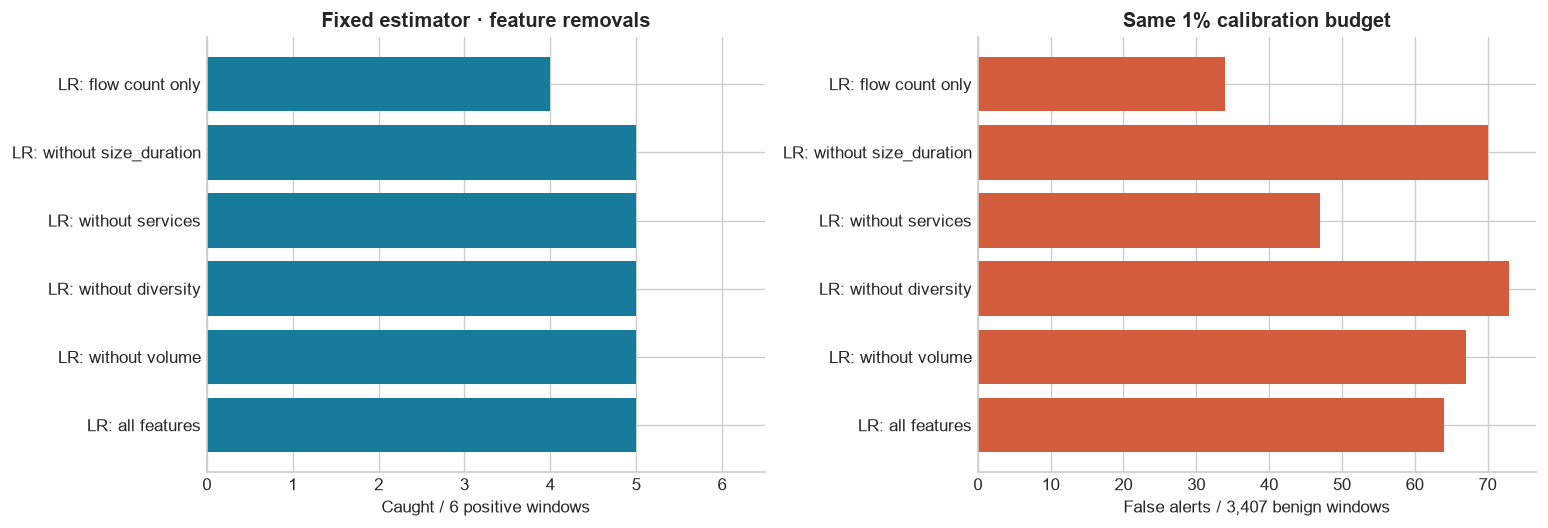

In [6]:
display(ablations[['method', 'feature_count', 'tp', 'fn', 'fp', 'tn', 'average_precision',
                  'delta_tp_vs_full', 'delta_fp_vs_full', 'changed_decisions']])
positive_count = int(data.loc[masks['development'], 'attack_flows'].gt(0).sum())
benign_count = int(masks['development'].sum()) - positive_count
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(ablations.method, ablations.tp, color='#177c9c')
axes[0].set(xlabel=f'Caught / {positive_count} positive windows', xlim=(0, positive_count + .5),
            xticks=range(positive_count + 1), title='Fixed estimator · feature removals')
axes[1].barh(ablations.method, ablations.fp, color='#d35c3c')
axes[1].set(xlabel=f'False alerts / {benign_count:,} benign windows', title='Same 1% calibration budget')
finish(fig, 'robustness_01_ablation')

### **Feature Ablation Interpretation**

Read caught positives and false alerts together. Deltas compare the same development entities
with the full-feature fit. A removal can reduce false alerts while missing more attack windows;
an apparent improvement is exploratory evidence for another study. The experiment does not
establish that a service feature transfers to another attack family or capture.

### **Measure Alert-Budget Sensitivity**

,method,target,calibration_benign_windows,calibration_allowed_false_alerts,calibration_false_alerts,cutoff,tp,fn,fp,false_positives_per_1000
0,LR: all features,0.001,1242,1,1,6.081963e-03,5,1,31,9.098914
1,LR: all features,0.005,1242,6,6,2.394093e-03,5,1,38,11.153507
2,LR: all features,0.010,1242,12,12,1.193150e-03,5,1,64,18.784855
3,LR: all features,0.020,1242,24,24,2.371875e-04,6,0,104,30.525389
4,LR: without volume,0.001,1242,1,1,7.490515e-03,5,1,28,8.218374
5,LR: without volume,0.005,1242,6,6,2.458126e-03,5,1,45,13.208101
6,LR: without volume,0.010,1242,12,12,1.473601e-03,5,1,67,19.665395
7,LR: without volume,0.020,1242,24,24,8.332733e-05,5,1,100,29.351335
8,LR: without diversity,0.001,1242,1,1,1.533269e-02,5,1,15,4.402700
9,LR: without diversity,0.005,1242,6,6,2.820017e-03,5,1,53,15.556208


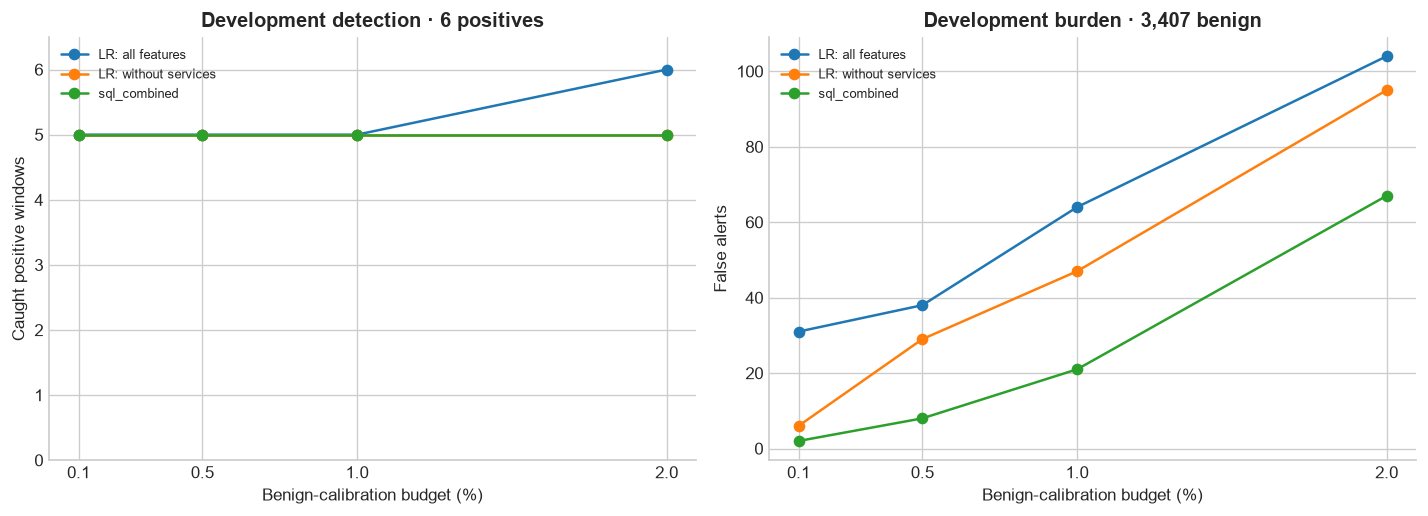

In [7]:
display(results[['method', 'target', 'calibration_benign_windows',
                 'calibration_allowed_false_alerts', 'calibration_false_alerts',
                 'cutoff', 'tp', 'fn', 'fp', 'false_positives_per_1000']])
focus = results.loc[results.method.isin(['LR: all features', 'LR: without services', 'sql_combined'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, rows in focus.groupby('method', sort=False):
    axes[0].plot(rows.target * 100, rows.tp, marker='o', label=name)
    axes[1].plot(rows.target * 100, rows.fp, marker='o', label=name)
axes[0].set(xlabel='Benign-calibration budget (%)', ylabel='Caught positive windows',
            ylim=(0, positive_count + .5), yticks=range(positive_count + 1),
            title=f'Development detection · {positive_count} positives')
axes[1].set(xlabel='Benign-calibration budget (%)', ylabel='False alerts',
            title=f'Development burden · {benign_count:,} benign')
for ax in axes:
    ax.set_xticks(np.array(ALERT_TARGETS) * 100)
    ax.legend(fontsize=8)
finish(fig, 'robustness_02_budgets')

### **Budget Interpretation**

Each point uses calibration scores only to set its threshold. Development false alerts can
exceed the calibration fraction because traffic changes over time. Budget changes are
operational scenarios; choosing the best point after viewing these results would require
a new validation population before any performance claim.

### **Inspect Missed Positives and False-Alert Concentration**

outcome,FN,FP,TN,TP
method,,,,
LR: all features,1,64,3343,5
sql_combined,1,21,3386,5


,method,src_ip,window_start,score,cutoff
2075,LR: all features,172.16.0.1,2017-07-04 10:30:00,0.000265,0.001193
5488,sql_combined,172.16.0.1,2017-07-04 10:30:00,0.001931,2.000000


,method,src_ip,false_alerts
2,LR: all features,192.168.10.15,11
0,LR: all features,192.168.10.12,9
7,LR: all features,192.168.10.51,8
1,LR: all features,192.168.10.14,6
5,LR: all features,192.168.10.19,6
6,LR: all features,192.168.10.5,6
8,LR: all features,192.168.10.8,6
9,LR: all features,192.168.10.9,5
4,LR: all features,192.168.10.17,4
3,LR: all features,192.168.10.16,3


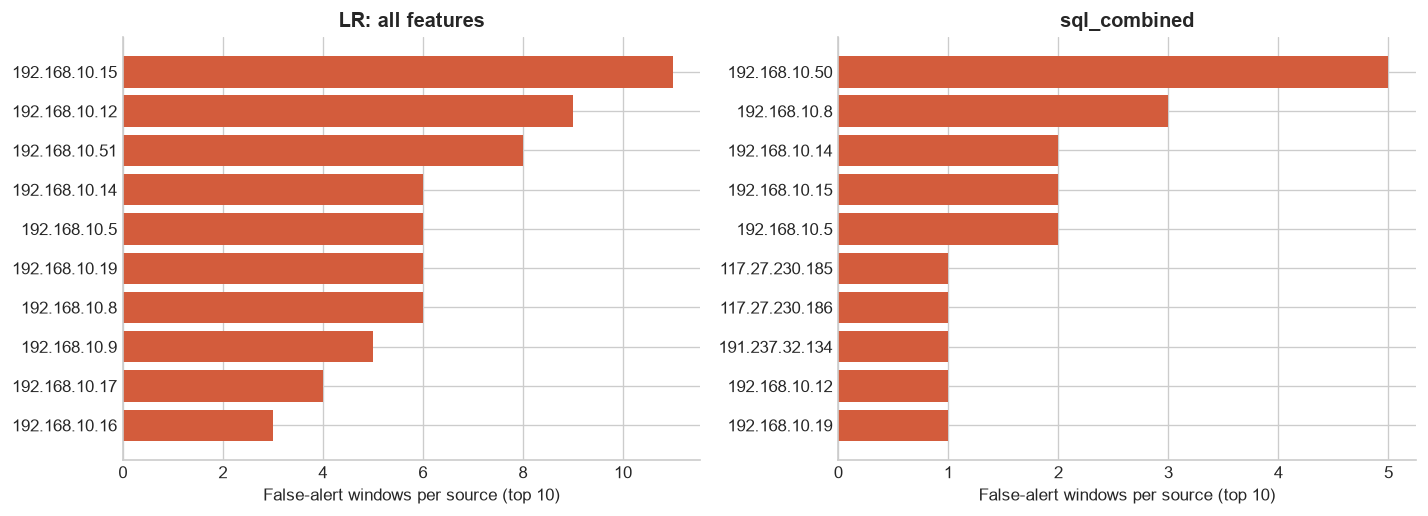

In [8]:
display(decisions.groupby(['method', 'outcome']).size().unstack(fill_value=0))
display(decisions.loc[decisions.outcome.eq('FN'),
                      ['method', 'src_ip', 'window_start', 'score', 'cutoff']])
false_alerts = decisions.loc[decisions.outcome.eq('FP')]
concentration = false_alerts.groupby(['method', 'src_ip']).size().rename('false_alerts').reset_index()
concentration.to_csv(output / 'false_alert_sources.csv', index=False)
display(concentration.sort_values(['method', 'false_alerts'], ascending=[True, False]).groupby('method').head(10))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, name in zip(axes, ['LR: all features', 'sql_combined']):
    rows = concentration.loc[concentration.method.eq(name)].nlargest(10, 'false_alerts')
    if rows.empty:
        ax.text(.5, .5, 'No false alerts', ha='center', transform=ax.transAxes)
    else:
        ax.barh(rows.src_ip, rows.false_alerts, color='#d35c3c')
        ax.invert_yaxis()
    ax.set(title=name, xlabel='False-alert windows per source (top 10)')
finish(fig, 'robustness_03_error_sources')

### **Error Analysis Interpretation**

Repeated false alerts from one source suggest a different investigation burden from alerts
scattered across sources. Counts still represent source-by-five-minute windows, not distinct
incidents. Source identifiers are displayed for retrospective evidence inspection only.
One recorded attack source and adjacent intervals leave no defensible independent-episode
uncertainty estimate, cross-day transfer result or production effectiveness claim.

---

# **Part 5: Conclusion**

### **Record the Measured Outcome and Next Experiment**

In [9]:
full = ablations.loc[ablations.method.eq('LR: all features')].iloc[0]
removed = ablations.loc[ablations.method.eq('LR: without services')].iloc[0]
sql = results.loc[results.method.eq('sql_combined') & results.target.eq(.01)].iloc[0]
display(Markdown(
    f'At the fixed 1% calibration budget, full-feature logistic regression caught **{full.tp}/{positive_count}** '
    f'positive windows with **{full.fp}/{benign_count:,}** false alerts. Removing service counts caught '
    f'**{removed.tp}/{positive_count}** with **{removed.fp}/{benign_count:,}** false alerts. '
    f'The combined SQL rule caught **{sql.tp}/{positive_count}** with **{sql.fp}/{benign_count:,}** false alerts. '
    'These are matched observations on the frozen development slice.'
))

At the fixed 1% calibration budget, full-feature logistic regression caught **5/6** positive windows with **64/3,407** false alerts. Removing service counts caught **5/6** with **47/3,407** false alerts. The combined SQL rule caught **5/6** with **21/3,407** false alerts. These are matched observations on the frozen development slice.

The three-notebook sequence now separates source fitness, candidate model tradeoffs, and
controlled sensitivity experiments. It provides a reproducible explanation of observed
behavior without promoting an exploratory result into an application decision.

Next, verify the corrected-source adapter and label policy, then predefine episode-separated
development and validation data across additional attack families. Repeat the registered
feature removals and budget scenarios on that population before choosing a model or operating
point. Measure SQL optimization and serving latency under their own bounded protocols.

Machine-readable evidence: `reports/research/robustness/`. Charts:
`reports/research/figures/robustness_*.png`.

---